# Atividade 4: correção dos dados e Hitachi no MTSA

**Luan César de Souza Nascimento** · estudante de Engenharia de Controle e Automação (UFPE) · COMPET Moura · 21/10/2026

| Campo | Informação |
|---|---|
| Repositório usado | [github.com/CristoferSilva/mtsa-tutorial-compet](https://github.com/CristoferSilva/mtsa-tutorial-compet), commit `a5959467eca45f930341783a7006affcae5e6e88` |
| Parte I | encontrar o problema em `get_tabular_sample_data()` |
| Parte II | treinar e avaliar o Hitachi no framework do tutorial, como no exemplo do GANF |
| Dados | CSV sintético do tutorial (5.000 linhas, 6 variáveis); não são dados da Moura |

Para rodar no Colab: **Ambiente de execução → Executar tudo**. Os módulos e o CSV estão embutidos no notebook, então não é preciso enviar o repositório nem baixar nada. A execução completa leva cerca de um minuto em CPU.

### Índice
1. [Ambiente e configuração](#ambiente)
2. [Origem dos dados e inspeção](#dados)
3. [Parte I: o erro em `get_tabular_sample_data()`](#parte1)
4. [Protocolo de avaliação e baseline](#protocolo)
5. [Parte II: Hitachi no framework](#parte2)
6. [Resultados por seed](#resultados)
7. [Gráficos e interpretação](#graficos)
8. [Limitações](#limites)
9. [Testes e reprodução](#testes)
10. [Respostas para a apresentação e referências](#apresentacao)

## 1. Ambiente e configuração <a id="ambiente" name="ambiente"></a>

Entrada: nada além deste notebook. Saída: uma pasta de trabalho com os módulos do tutorial, os da atividade e o CSV, todos conferidos por SHA-256.

Usamos só pacotes que já vêm no Colab (PyTorch, NumPy, pandas, scikit-learn, Matplotlib, tqdm). O pacote `mtsa` do PyPI tem outra interface; por isso o notebook usa a cópia do tutorial, e não `pip install mtsa`.

In [1]:
import hashlib
import importlib.util
import os
import sys
from pathlib import Path

os.environ['TQDM_DISABLE'] = '1'  # barras de progresso do treinador poluem a saída salva

import numpy as np
import pandas as pd
import sklearn
import torch
from IPython.display import Code, Markdown, display

EM_COLAB = 'google.colab' in sys.modules
PASTA = Path('/content/atividade4_mtsa') if EM_COLAB else Path.cwd() / 'atividade4_mtsa'
PASTA.mkdir(parents=True, exist_ok=True)
pd.DataFrame({'item': ['Colab', 'Python', 'PyTorch', 'NumPy', 'pandas', 'scikit-learn', 'pasta de trabalho'],
              'valor': [EM_COLAB, sys.version.split()[0], torch.__version__, np.__version__,
                        pd.__version__, sklearn.__version__, str(PASTA)]})

,item,valor
0,Colab,False
1,Python,3.12.14
2,PyTorch,2.5.1+cpu
3,NumPy,2.3.5
4,pandas,3.0.1
5,scikit-learn,1.9.1
6,pasta de trabalho,C:\Users\Admin\AppData\Local\Temp\atividade4_l...


In [2]:
# @title Arquivos embutidos (recolhido; abra para inspecionar)
# Cópia literal dos arquivos; os hashes foram calculados sobre os bytes originais.
SOURCE_FILES = {
 "mtsa/__init__.py": "from importlib import import_module\n\n__all__ = [\n    'TRCVAE',\n    'GANF',\n    'RANSynCoders',\n    'OSVM',\n    'IForest',\n    'Transformer',\n    'Hitachi',\n    'HitachiDCASE2020',\n    'MFCCMix',\n    'BARNNLSTM',\n    'calculate_aucroc',\n    'calculate_confusion_matrix',\n    'files_train_test_split',\n    'files_train_test_split_dcase2020_task2',\n    'files_train_test_split_combined',\n    'build_signal_processing_steps',\n    'Wav2Array',\n    'Demux2Array',\n    'AbnormalSplit',\n    'NORMAL',\n    'ABNORMAL',\n    'TRVAE',\n    'TRCVAES',\n]\n\n_NAME_TO_MODULE = {\n    'TRCVAE': '.models',\n    'GANF': '.models.hybrid',\n    'RANSynCoders': '.models',\n    'OSVM': '.models',\n    'TRVAE': '.models',\n    'IForest': '.models',\n    'TRCVAES': '.models',\n    'Transformer': '.models',\n    'Hitachi': '.models',\n    'HitachiDCASE2020': '.models',\n    'MFCCMix': '.models',\n    'BARNNLSTM': '.models',\n    'calculate_aucroc': '.utils.metrics',\n    'calculate_confusion_matrix': '.utils.metrics',\n    'files_train_test_split': '.utils.utils',\n    'files_train_test_split_dcase2020_task2': '.utils.utils',\n    'files_train_test_split_combined': '.utils.utils',\n    'build_signal_processing_steps': '.utils.utils',\n    'Wav2Array': '.utils.utils',\n    'Demux2Array': '.utils.utils',\n    'AbnormalSplit': '.utils.utils',\n    'NORMAL': '.utils.utils',\n    'ABNORMAL': '.utils.utils',\n}\n\n\ndef __getattr__(name):\n    try:\n        module_name = _NAME_TO_MODULE[name]\n    except KeyError as exc:\n        raise AttributeError(f'module {__name__!r} has no attribute {name!r}') from exc\n    module = import_module(module_name, __name__)\n    value = getattr(module, name)\n    globals()[name] = value\n    return value\n\n\ndef __dir__():\n    return sorted(list(globals().keys()) + __all__)\n",
 "mtsa/loss.py": "import torch\nimport torch.nn as nn\nfrom typing import Protocol, Any, Tuple, runtime_checkable\n\n\n@runtime_checkable\nclass Loss(Protocol):\n    def calculate(\n        self, \n        X: torch.Tensor, \n        y: torch.Tensor, \n        model: nn.Module, \n        *args: Any, \n        **kwargs: Any\n    ) -> Tuple[Any, ...]:\n        ...\n        \n    def __call__(\n        self, \n        X: torch.Tensor, \n        y: torch.Tensor, \n        model: nn.Module, \n        *args: Any, \n        **kwargs: Any\n    ) -> Tuple[Any, ...]:\n        ...\n",
 "mtsa/trainer.py": "import torch.nn as nn\nimport torch\nfrom torch.utils.data import DataLoader\nfrom typing import Protocol, runtime_checkable, Optional, Any\nfrom mtsa.loss import Loss\nfrom abc import ABC\n\n@runtime_checkable\nclass Trainer(Protocol):    \n    def fit(self, \n            model: nn.Module, \n            optimizer: torch.optim.Optimizer, \n            loss: Loss, \n            train_loader: DataLoader, \n            val_loader: Optional[DataLoader], \n            **kwargs: Any\n        ) -> nn.Module:\n        ...\n\nclass BaseTrainer(ABC):\n    def __init__(self):\n        self.min_error=None\n        self.time=None\n\n    def __call__(self, \n                model: nn.Module, \n                optimizer: torch.optim.Optimizer, \n                loss: Loss, \n                train_loader: DataLoader, \n                val_loader: Optional[DataLoader] = None, \n                **kwargs: Any\n            ) -> nn.Module:\n        return self.fit(model, optimizer, loss, train_loader, val_loader, **kwargs)\n\n    def fit(self, \n            model: nn.Module, \n            optimizer: torch.optim.Optimizer, \n            loss: Loss, \n            train_loader: DataLoader, \n            val_loader: Optional[DataLoader] = None, \n            **kwargs: Any\n        ) -> nn.Module:\n        raise NotImplementedError",
 "mtsa/predictor.py": "import torch.nn as nn\nfrom torch.utils.data import DataLoader\nfrom typing import Protocol, runtime_checkable, List, Any\nfrom abc import ABC\n\n@runtime_checkable\nclass Predictor(Protocol):    \n    def predict(self, \n            model: nn.Module, \n            dataloader: DataLoader, \n        ) -> List[float]:\n        ...\n\nclass BasePredictor(ABC):\n    def __init__(self):\n        self.time=None\n\n    def __call__(self, model: nn.Module, dataloader: DataLoader) -> Any:\n        return self.predict(model, dataloader)\n\n    def predict(self, model: nn.Module, dataloader: DataLoader) -> Any:\n        raise NotImplementedError",
 "mtsa/losses/mse_loss.py": "import torch\nimport torch.nn as nn\nfrom typing import Tuple, Any\n\nclass MSELoss:\n    def __init__(self):\n        self.criterion = nn.MSELoss()\n\n    def calculate(\n        self, \n        X: torch.Tensor, \n        y: torch.Tensor, \n        model: nn.Module, \n        **kwargs: Any, \n    ) -> Tuple[Any, ...]:\n        y_hat = model(X)\n        loss = self.criterion(y_hat, y)\n        return (loss, )\n\n    def __call__(self, X: torch.Tensor, y: torch.Tensor, model: nn.Module, **kwargs: Any) -> Tuple[Any, ...]:\n        return self.calculate(X, y, model, **kwargs)\n\n",
 "mtsa/models/__init__.py": "from importlib import import_module\n\n__all__ = [\n    'BARNNLSTM',\n    'GANF',\n    'OSVM',\n    'TRCVAE',\n    'TRVAE',\n    'TRCVAES'\n    'Hitachi',\n    'HitachiDCASE2020',\n    'IForest',\n    'MFCCMix',\n    'RANSynCoders',\n    'Transformer'\n]\n\n_NAME_TO_MODULE = {\n    'Hitachi': '.hitachi',\n    'HitachiDCASE2020': '.hitachi',\n    'MFCCMix': '.mfccmix',\n    'GANF': '.ganf',\n    'RANSynCoders': '.ransyncorders',\n    'IForest': '.isolationforest',\n    'OSVM': '.oneClassSVM',\n    'Transformer': '.transformer',\n    'TRCVAE': '.trcvae',\n    'BARNNLSTM': '.barnn_lstm',\n    'TRVAE': '.trvae',\n    'TRCVAES': '.trcvaes',\n}\n\n\ndef __getattr__(name):\n    try:\n        module_name = _NAME_TO_MODULE[name]\n    except KeyError as exc:\n        raise AttributeError(f'module {__name__!r} has no attribute {name!r}') from exc\n    module = import_module(module_name, __name__)\n    value = getattr(module, name)\n    globals()[name] = value\n    return value\n\n\ndef __dir__():\n    return sorted(list(globals().keys()) + __all__)\n",
 "mtsa/models/hitachi.py": "import torch\nimport torch.nn as nn\n\n\nclass Hitachi(nn.Module):\n    def __init__(self, input_dim):\n        super().__init__()\n        self.input_dim = input_dim\n        self.encoder = nn.Sequential(\n            nn.Linear(self.input_dim, 64),\n            nn.ReLU(),\n            nn.Linear(64, 64),\n            nn.ReLU(),\n            nn.Linear(64, 8),\n            nn.ReLU()\n        )\n\n        self.decoder = nn.Sequential(\n            nn.Linear(8, 64),\n            nn.ReLU(),\n            nn.Linear(64, 64),\n            nn.ReLU(),\n            nn.Linear(64, self.input_dim),\n        )\n\n    def forward(self, X):\n        X_encoded = self.encoder(X)\n        X_decoded = self.decoder(X_encoded)\n        return X_decoded\n",
 "mtsa/trainers/unsupervised_trainer.py": "import torch\nimport torch.nn as nn\nimport time\nfrom torch.utils.data import DataLoader\nfrom typing import Optional, Any\nfrom mtsa.loss import Loss\nfrom tqdm import tqdm\nfrom mtsa.trainer import BaseTrainer\n\nclass UnsupervisedTrainer(BaseTrainer):\n    def __init__(self):\n        super().__init__()\n    \n    def fit(self, \n            model: nn.Module, \n            optimizer: torch.optim.Optimizer, \n            loss: Loss, \n            train_loader: DataLoader, \n            val_loader: Optional[DataLoader] = None, \n            **kwargs: Any\n        ) -> nn.Module:\n        epochs = kwargs.get('epochs', 30)\n        pbar = tqdm(range(epochs), desc=f\"Training | {epochs} Epochs\", unit=\"epoch\", dynamic_ncols=True)\n        start_time = time.time()\n        \n        for epoch in pbar:\n            model.train()\n            total_loss = 0.0\n\n            for x_batch, _ in train_loader:\n                x_batch = x_batch\n                \n                batch_loss, = loss(x_batch, x_batch, model)\n  \n                optimizer.zero_grad()\n                batch_loss.backward()\n                optimizer.step()\n\n                total_loss += batch_loss.item()\n                \n            avg_loss = total_loss / len(train_loader)\n\n            pbar.set_postfix({\"loss\": f\"{avg_loss:.4f}\"})\n\n        elapsed_time = time.time() - start_time\n        self.time = elapsed_time\n        self.min_error = avg_loss\n        return model",
 "mtsa/predictors/standard_predictor.py": "import numpy as np\nimport torch\nfrom torch import nn\nfrom torch.utils.data import DataLoader\n\nfrom mtsa.loss import Loss\nfrom mtsa.predictor import BasePredictor\nfrom mtsa.utils.data import build_window_tensor, coerce_2d_array, compute_window_starts\n\n\nclass StandardPredictor(BasePredictor):\n    def __init__(self):\n        super().__init__()\n\n    def predict(\n        self, function: nn.Module | Loss, dataloader: DataLoader, pointwise: bool, aggregation=\"max\", device=None\n    ):\n\n        self.device = self._resolve_device(device)\n\n        if dataloader is None:\n            raise ValueError(\"Dataloader is none\")\n\n        if type(function) is nn.Module:\n            function.eval()\n\n        y_hat = None\n        y_true = None\n\n        with torch.no_grad():\n            if pointwise:\n                y_hat, y_true = self.__predict_points(\n                    function=function, dataloader=dataloader, aggregation=aggregation)\n            else:\n                y_hat, y_true = self.__predict_windows(function, dataloader)\n\n        y_hat = np.array(y_hat).reshape(-1,1)\n        y_true = np.array(y_true).reshape(-1,1)\n        return y_hat, y_true\n\n    def __predict_windows(self, function, dataloader):\n        y_hat_list = [], y_true_list = []\n        for x_batch, y_batch in dataloader:\n            y_hat = function(x_batch)\n            y_hat_list.append(y_hat)\n            y_true_list.append(y_batch)\n\n        return y_hat_list, y_true_list\n\n    def __predict_points(self, function: nn.Module, dataloader: DataLoader, aggregation=\"max\"):\n        X = dataloader.dataset.X\n        X = coerce_2d_array(X)\n        y = dataloader.dataset.y\n\n        effective_window_size, starts = compute_window_starts(\n            X.shape[0], dataloader.dataset.window_size, dataloader.dataset.stride, ensure_full_coverage=True\n        )\n\n        if aggregation not in {\"max\", \"mean\"}:\n            raise ValueError(\n                f\"Unknown aggregation: {aggregation}. Expected one of ['max', 'mean'].\")\n\n        if aggregation == \"max\":\n            point_scores = np.full(X.shape[0], -np.inf, dtype=float)\n        else:\n            point_scores = np.zeros(X.shape[0], dtype=float)\n            counts = np.zeros(X.shape[0], dtype=float)\n\n        with torch.no_grad():\n            for start in starts:\n                x_window = build_window_tensor(\n                    X, start, effective_window_size).unsqueeze(0).to(self.device)\n                window_score = float(function(x_window))\n                end = start + effective_window_size\n                if aggregation == \"max\":\n                    point_scores[start:end] = np.maximum(\n                        point_scores[start:end], window_score)\n                else:\n                    point_scores[start:end] += window_score\n                    counts[start:end] += 1.0\n\n        if aggregation == \"mean\":\n            point_scores = point_scores / counts\n\n        y_hat = point_scores.tolist()\n        return y_hat, y\n\n    @staticmethod\n    def _resolve_device(device):\n        if isinstance(device, torch.device):\n            return device\n        if isinstance(device, int):\n            if torch.cuda.is_available():\n                return torch.device(f\"cuda:{device}\")\n            return torch.device(\"cpu\")\n        if device is None:\n            return torch.device(\"cuda:0\" if torch.cuda.is_available() else \"cpu\")\n        return torch.device(device)\n\n",
 "mtsa/utils/__init__.py": "",
 "mtsa/utils/data.py": "import torch\nfrom torch.utils.data import DataLoader, Dataset\nimport numpy as np\n\ndef get_dataloader(\n    X,\n    y,\n    window_size=20,\n    stride_size=20,\n    batch_size=32,\n    shuffle=False,\n    num_workers=0,\n    persistent_workers=False,\n    drop_last=True,\n):\n    Xy_dataloader = DataLoader(\n        Data(X=X, y=y, window_size=window_size, stride_size=stride_size),\n        batch_size=batch_size,\n        shuffle=shuffle,\n        num_workers=num_workers,\n        persistent_workers=persistent_workers,\n        drop_last=drop_last,\n    )\n    return Xy_dataloader\n\n\ndef build_window_tensor(X, start, window_size):\n    start = int(start)\n    end = start + int(window_size)\n    x_window = X[start:end].reshape(int(window_size), -1, 1)\n    return torch.from_numpy(x_window.copy()).float()\n\ndef coerce_2d_array(X):\n    X = X.reshape((X.shape[0]* X.shape[1], X.shape[2]))\n    if isinstance(X, list):\n        if len(X) == 1:\n            X = X[0]\n        else:\n            X = np.asarray(X)\n    X = np.asarray(X)\n    if X.ndim != 2:\n        raise ValueError('X should be a 2D array')\n    return X\n\ndef compute_window_starts(n_rows, window_size, stride_size, ensure_full_coverage=False):\n    n_rows = int(n_rows)\n    window_size = int(window_size)\n    stride_size = int(stride_size)\n\n    if n_rows <= 0:\n        raise ValueError('n_rows must be positive')\n    if window_size <= 0:\n        raise ValueError('window_size must be positive')\n    if stride_size <= 0:\n        raise ValueError('stride_size must be positive')\n\n    effective_window_size = min(window_size, n_rows)\n    starts = np.arange(0, n_rows - effective_window_size + 1, stride_size, dtype=int)\n    if starts.size == 0:\n        starts = np.array([0], dtype=int)\n\n    if ensure_full_coverage:\n        if stride_size > effective_window_size:\n            raise ValueError(\n                'Point-level scoring requires stride_size <= effective_window_size so every timestamp is covered.'\n            )\n        last_start = n_rows - effective_window_size\n        if starts[-1] != last_start:\n            starts = np.unique(np.append(starts, last_start))\n\n    return effective_window_size, starts\n\n\nclass Data(Dataset):\n    def __init__(self, X, y, window_size=20, stride_size=20):\n        self.coerce(X, y)\n        self.window_size = window_size\n        self.stride = stride_size\n        self.n_files = self.X.shape[0]  # number F of data matrix TxD\n        self.n_datapoints = self.X.shape[1]  # T\n        self.n_features = self.X.shape[2]  # D\n\n        self.windows_per_file = 0\n        start = 0\n        while start + window_size <= self.n_datapoints:\n            self.windows_per_file += 1\n            start += stride_size\n        self.total_windows = self.n_files * self.windows_per_file\n\n    def coerce(self, X, y):\n        if X.ndim > 3:\n            raise ValueError(\"X should be 2D or 3D array\")\n\n        elif X.ndim == 2:\n            X = X.reshape(-1, X.shape[0], X.shape[1])\n            y = y.reshape(-1, y.shape[0])\n        elif y.shape[0] == X.shape[0]:\n            y = np.array([np.full(X.shape[1], y_i) for y_i in y])\n\n        if (y.shape[0] > 1 and y.shape[0]*y.shape[1] != X.shape[0]*X.shape[1]) or (y.shape[0] == 1 and X.shape[1] != y.shape[1]):\n            raise ValueError(\"X and y must have the same number of rows.\")\n\n        self.X = X\n        self.y = y\n\n    def __len__(self):\n        return self.total_windows\n\n    def __getitem__(self, idx):\n        file_idx = idx // self.windows_per_file\n        window_idx = idx % self.windows_per_file\n        start = window_idx * self.stride\n        end = start + self.window_size\n        if end > self.n_datapoints:\n            raise IndexError(\"It was not possible create a window: end > n_datapoints\")\n        X_windowed = self.X[file_idx][start:end]\n        y_windowed = self.y[file_idx][start:end]\n        return X_windowed, y_windowed\n",
 "examples/sample_data_utils.py": "\"\"\"Dados do tutorial; 0 = normal, 1 = anômalo. Anomalias são sintéticas.\"\"\"\nfrom pathlib import Path\nfrom typing import Any, Literal, overload\n\nimport numpy as np\nimport pandas as pd\n\n\ndef get_acoustic_sample_data():\n    from mtsa import files_train_test_split\n    path_input_1 = Path(__file__).resolve().parent / 'sample_data' / 'machine_type_1' / 'id_00'\n    X_train, X_test, y_train, y_test = files_train_test_split(str(path_input_1))\n    return X_train, y_train, X_test, y_test\n\n\ndef set_abnormal_data(x, step, y_test, features=None, magnitude=2, start_point=None):\n    \"\"\"Quatro intervalos de duração step, in-place; início zero é válido.\n\n    Correção: o fim do primeiro intervalo é início + duração, não step.\n    \"\"\"\n    first_start = step if start_point is None else start_point\n    intervals = [\n        (first_start, first_start + step),\n        (2 * step, 3 * step),\n        (4 * step, 5 * step),\n        (len(x) - (100 + step), len(x) - 100),\n    ]\n    if step <= 0 or len(y_test) != len(x) or any(\n        not 0 <= start < end <= len(x) for start, end in intervals\n    ):\n        raise ValueError('Intervalos devem ser não vazios e estar dentro dos dados.')\n    if features is None:\n        features = slice(None)\n    anomaly = magnitude * np.sin(np.pi / 4)\n    for start, end in intervals:\n        x[start:end, features] += anomaly\n        y_test[start:end] = 1\n    return x, y_test\n\n\n@overload\ndef get_tabular_sample_data(*, split_mode: str = 'chronological', return_metadata: Literal[True]) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray, dict[str, Any]]: ...\n\n\n@overload\ndef get_tabular_sample_data(*, split_mode: str = 'chronological', return_metadata: Literal[False] = False) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]: ...\n\n\ndef get_tabular_sample_data(*, split_mode='chronological', return_metadata=False):\n    \"\"\"Retorna X_train, y_train, X_test, y_test.\n\n    chronological: primeiros 60% normais para desenvolvimento; últimos 40%\n    para teste, com anomalias injetadas apenas no teste.\n    legacy: montagem por classe do tutorial, apenas para comparação.\n    \"\"\"\n    data_path = Path(__file__).resolve().parent / 'linear_ts_with_confounder_n5000_vars6_lag2_gaussian.csv'\n    df = pd.read_csv(data_path)\n    df = df.drop(columns=[\"U\"])\n    df = df.drop(columns=[\"time\"])\n\n    X = df.to_numpy()\n    y = np.zeros(X.shape[0])\n\n    if split_mode == 'chronological':\n        cut = int(0.6 * len(X))\n        X_train, X_test = X[:cut].copy(), X[cut:].copy()\n        y_train = np.zeros(cut, dtype=int)\n        y_test = np.zeros(len(X_test), dtype=int)\n        train_indices, test_indices = np.arange(cut), np.arange(cut, len(X))\n        X_test, y_test = set_abnormal_data(X_test, 200, y_test, features=[4, 5], magnitude=2, start_point=150)\n        X_test, y_test = set_abnormal_data(X_test, 13, y_test, features=[1, 0], magnitude=7, start_point=200)\n        result = (X_train, y_train, X_test, y_test)\n        if return_metadata:\n            return (*result, {'split_mode': split_mode, 'train_indices': train_indices.tolist(),\n                             'test_indices': test_indices.tolist(), 'features': list(df.columns)})\n        return result\n    if split_mode != 'legacy':\n        raise ValueError(\"split_mode deve ser 'chronological' ou 'legacy'.\")\n\n    X, y = set_abnormal_data(X, 200, y, features=[4, 5], magnitude=2, start_point=150)\n    X, y = set_abnormal_data(X, 13, y, features=[1, 0], magnitude=7, start_point=200)\n    mask_normal = y == 0\n    mask_abnormal = y == 1\n\n    X_normal = X[mask_normal]\n    X_abnormal = X[mask_abnormal]\n\n    anomaly_quantity = len(X_abnormal)\n\n    X_test = np.vstack([X_normal[:anomaly_quantity], X_abnormal])\n\n    X_train = X_normal[anomaly_quantity:]\n\n    y_test = np.concatenate([np.zeros(anomaly_quantity, dtype=int), np.ones(anomaly_quantity, dtype=int)])\n\n    y_train = np.zeros_like(X_train[:, 0])\n\n    if return_metadata:\n        normal, abnormal = np.flatnonzero(mask_normal), np.flatnonzero(mask_abnormal)\n        return X_train, y_train, X_test, y_test, {\n            'split_mode': split_mode, 'train_indices': normal[anomaly_quantity:].tolist(),\n            'test_indices': np.concatenate([normal[:anomaly_quantity], abnormal]).tolist(),\n            'features': list(df.columns)}\n    return X_train, y_train, X_test, y_test\n",
 "mtsa/predictors/hitachi_score.py": "\"\"\"Adapta a reconstrução do Hitachi ao StandardPredictor do framework.\"\"\"\nimport torch\nfrom torch import nn\n\n\nclass HitachiScore(nn.Module):\n    \"\"\"MSE por janela: maior = mais anômalo.\n\n    StandardPredictor entrega (batch, tempo, variáveis, 1). O Hitachi\n    reconstrói a última dimensão de (batch, tempo, variáveis).\n    \"\"\"\n    def __init__(self, model):\n        super().__init__()\n        self.model = model\n\n    def forward(self, x):\n        if x.ndim == 4 and x.shape[-1] == 1:\n            x = x.squeeze(-1)\n        if x.ndim != 3 or x.shape[-1] != self.model.input_dim:\n            raise ValueError('Esperado (batch, tempo, input_dim), com canal singleton opcional.')\n        error = torch.square(x - self.model(x))\n        return error.mean(dim=(1, 2))\n",
 "atividade4/__init__.py": "\"\"\"Experimento reproduzível da Atividade 4.\"\"\"\n",
 "atividade4/experimento.py": "\"\"\"Treina e avalia o Hitachi com os componentes do MTSA do tutorial.\n\nExecutar da raiz: python -m atividade4.experimento\nO notebook da entrega importa estas mesmas funções; CONFIG é o único lugar\ncom seeds, épocas, lote, taxa de aprendizado, divisão e regra do limiar.\n\"\"\"\nimport json\nimport platform\nimport time\nfrom pathlib import Path\n\nimport numpy as np\nimport pandas as pd\nimport torch\nfrom sklearn.metrics import average_precision_score, confusion_matrix, roc_auc_score\nfrom sklearn.preprocessing import StandardScaler\n\nfrom examples.sample_data_utils import get_tabular_sample_data\nfrom mtsa.losses.mse_loss import MSELoss\nfrom mtsa.models.hitachi import Hitachi\nfrom mtsa.predictors.hitachi_score import HitachiScore\nfrom mtsa.predictors.standard_predictor import StandardPredictor\nfrom mtsa.trainers.unsupervised_trainer import UnsupervisedTrainer\nfrom mtsa.utils.data import get_dataloader\n\nROOT = Path(__file__).resolve().parents[1]\nOUTPUT = ROOT / 'atividade4' / 'resultados'\n\n# Protocolo definido antes da avaliação; nenhum valor foi escolhido pelo teste.\nCONFIG = {\n    'seeds': [11, 22, 33, 42, 55],\n    'epochs': 30,\n    'batch_size': 64,\n    'learning_rate': 0.001,\n    'window_size': 1,\n    'train_rows': 2500,            # linhas 0-2499 do bloco de desenvolvimento\n    'threshold_quantile': 0.99,    # sobre escores normais da validação\n    'saved_seed': 42,              # seed cujo modelo e predições são salvos\n    'torch_threads': 2,\n}\nSEEDS = tuple(CONFIG['seeds'])\nEPOCHS = CONFIG['epochs']\n\n\ndef loader(x, y, *, shuffle=False, config=CONFIG):\n    # Autoencoder reconstrói cada vetor de seis variáveis: janela 1.\n    return get_dataloader(np.asarray(x, dtype=np.float32), np.asarray(y),\n                          window_size=config['window_size'], stride_size=1,\n                          batch_size=config['batch_size'], shuffle=shuffle,\n                          drop_last=False, num_workers=0)\n\n\ndef score(model, x, y, config=CONFIG):\n    function = HitachiScore(model).eval()\n    scores, labels = StandardPredictor().predict(\n        function=function, dataloader=loader(x, y, config=config), pointwise=True,\n        aggregation='mean', device='cpu')\n    return scores.ravel(), labels.ravel().astype(int)\n\n\ndef metrics(y, scores, threshold):\n    pred = (scores > threshold).astype(int)\n    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()\n    return {'roc_auc': float(roc_auc_score(y, scores)),\n            'average_precision': float(average_precision_score(y, scores)),\n            'f1': float(2 * tp / (2 * tp + fp + fn)) if 2 * tp + fp + fn else 0.,\n            'precision': float(tp / (tp + fp)) if tp + fp else 0.,\n            'recall': float(tp / (tp + fn)) if tp + fn else 0.,\n            'far': float(fp / (fp + tn)), 'mar': float(fn / (fn + tp)),\n            'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),\n            'threshold': float(threshold)}\n\n\ndef audit_original():\n    \"\"\"Reproduz a primeira fatia original e compara seu efeito com a correção.\"\"\"\n    path = ROOT / 'atividade4/fontes/original_sample_data_utils.py'\n    source = path.read_text(encoding='utf-8')\n    if '(start_point or step, step)' not in source:\n        raise ValueError('A fonte preservada não contém o intervalo original esperado.')\n    start_point, step = 200, 13\n    old_start, old_end = start_point or step, step\n    old_y = np.zeros(1000)\n    old_y[old_start:old_end] = 1\n    from examples.sample_data_utils import set_abnormal_data\n    _, new_y = set_abnormal_data(np.zeros((1000, 6)), 13, np.zeros(1000),\n                                features=[0], start_point=200, magnitude=7)\n    return {'original_first_interval': [200, 13], 'corrected_first_interval': [200, 213],\n            'original_positive_rows_200_213': int(old_y[200:213].sum()),\n            'corrected_positive_rows_200_213': int(new_y[200:213].sum()),\n            'original_other_first_interval': [150, 200],\n            'corrected_other_first_interval': [150, 350],\n            'sine_is_constant': True,\n            'note': 'magnitude * sin(pi/4) é constante: deslocamento, não senoide temporal.'}\n\n\ndef prepare_data(config=CONFIG):\n    \"\"\"Divide em treino/validação/teste e padroniza com estatísticas do treino.\"\"\"\n    xdev, ydev, xtest, ytest, metadata = get_tabular_sample_data(return_metadata=True)\n    cut = config['train_rows']\n    xfit, xval = xdev[:cut], xdev[cut:]\n    scaler = StandardScaler().fit(xfit)\n    fit, val, test = [np.asarray(scaler.transform(x), dtype=np.float32) for x in [xfit, xval, xtest]]\n    return {'fit': fit, 'val': val, 'test': test, 'yfit': ydev[:cut], 'yval': ydev[cut:],\n            'ytest': ytest, 'scaler': scaler, 'metadata': metadata}\n\n\ndef train_one_seed(seed, data, config=CONFIG):\n    \"\"\"Modelo, perda, otimizador, treinador e preditor do framework; limiar pela validação.\"\"\"\n    torch.manual_seed(seed)\n    np.random.seed(seed)\n    model = Hitachi(input_dim=data['fit'].shape[1]).float()\n    optimizer = torch.optim.Adam(model.parameters(), lr=config['learning_rate'])\n    trainer = UnsupervisedTrainer()\n    started = time.perf_counter()\n    trainer.fit(model=model, optimizer=optimizer, loss=MSELoss(),\n                train_loader=loader(data['fit'], data['yfit'], shuffle=True, config=config),\n                epochs=config['epochs'])\n    elapsed = time.perf_counter() - started\n    val_scores, _ = score(model, data['val'], data['yval'], config)\n    threshold = float(np.quantile(val_scores, config['threshold_quantile']))\n    test_scores, test_labels = score(model, data['test'], data['ytest'], config)\n    record = {'model': 'Hitachi', 'seed': seed, **metrics(test_labels, test_scores, threshold),\n              'train_seconds': elapsed, 'train_final_loss': float(trainer.min_error)}\n    return record, model, val_scores, test_scores\n\n\ndef baseline(data, config=CONFIG):\n    \"\"\"Regra fixa: média dos quadrados das variáveis padronizadas pelo treino.\"\"\"\n    val_baseline = np.square(data['val']).mean(axis=1)\n    test_baseline = np.square(data['test']).mean(axis=1)\n    threshold = np.quantile(val_baseline, config['threshold_quantile'])\n    return {'model': 'Distância ao normal', **metrics(data['ytest'], test_baseline, threshold)}, test_baseline\n\n\ndef summarize(records):\n    return {key: {'mean': float(np.mean([r[key] for r in records])),\n                  'sd': float(np.std([r[key] for r in records], ddof=1))}\n            for key in ['roc_auc', 'average_precision', 'f1', 'precision', 'recall', 'far', 'mar']}\n\n\ndef run(config=CONFIG, output=OUTPUT):\n    output.mkdir(parents=True, exist_ok=True)\n    torch.set_num_threads(config['torch_threads'])\n    torch.use_deterministic_algorithms(True)\n    data = prepare_data(config)\n    fit, val, test, ytest, scaler, metadata = (data[k] for k in ['fit', 'val', 'test', 'ytest', 'scaler', 'metadata'])\n    audit = audit_original()\n    provenance = json.loads((ROOT/'atividade4/fontes/proveniencia.json').read_text(encoding='utf-8'))\n    settings = {**config, 'threshold_rule': 'percentil 99 dos escores normais de validação',\n                'train_rows': len(fit), 'validation_rows': len(val), 'test_rows': len(test),\n                'test_normals': int((ytest == 0).sum()), 'test_anomalies': int(ytest.sum()),\n                'architecture': '6 -> 64 -> 64 -> 8 -> 64 -> 64 -> 6; ReLU; saída linear',\n                'device': 'cpu', 'dataset': 'sintético do tutorial; desvios constantes injetados',\n                'selection': 'Sem busca de hiperparâmetros e sem escolha de seed pelo teste.'}\n    records = []\n    for seed in config['seeds']:\n        record, model, _, test_scores = train_one_seed(seed, data, config)\n        records.append(record)\n        print(json.dumps(record), flush=True)\n        if seed == config['saved_seed']:\n            torch.save({'state_dict': model.state_dict(), 'input_dim': 6, 'seed': seed,\n                        'threshold': record['threshold'], 'scaler_mean': np.asarray(scaler.mean_).tolist(),\n                        'scaler_scale': np.asarray(scaler.scale_).tolist()}, output/'hitachi_seed42.pt')\n            pd.DataFrame({'time': metadata['test_indices'], 'y_true': ytest,\n                          'score_hitachi': test_scores}).to_csv(output/'predicoes_seed42.csv', index=False)\n\n    base, _ = baseline(data, config)\n    frame = pd.DataFrame(records)\n    report = {'provenance': provenance, 'settings': settings, 'bug_evidence': audit,\n              'environment': {'python': platform.python_version(), 'torch': torch.__version__,\n                              'numpy': np.__version__, 'pandas': pd.__version__},\n              'runs': records, 'summary': summarize(records), 'baseline': base,\n              'limitations': ['Um único arquivo sintético e uma divisão temporal fixa.',\n                              'Anomalias adicionadas têm amplitudes muito maiores que a variação normal.',\n                              'Desvio entre seeds mede apenas inicialização/ordem de treino, não novos conjuntos.',\n                              'Não demonstra desempenho em dados reais nem superioridade sobre GANF.',\n                              'Hitachi já existia no tutorial; contribuição é a integração completa e a avaliação.',\n                              'Com seis entradas, a camada de oito unidades não comprime: adapta-se a arquitetura existente.']}\n    frame.to_csv(output/'metricas_seeds.csv', index=False)\n    (output/'resultados.json').write_text(json.dumps(report, ensure_ascii=False, indent=2), encoding='utf-8')\n    (output/'auditoria_particao.json').write_text(json.dumps(metadata), encoding='utf-8')\n    print('RESULTADOS', output, flush=True)\n    return report\n\n\nif __name__ == '__main__':\n    run()\n",
 "atividade4/fontes/original_sample_data_utils.py": "import os\nimport sys\nimport numpy as np\nimport pandas as pd\n\nsys.path.append(\"..\")\n\nfrom mtsa import files_train_test_split\n\ndef get_acoustic_sample_data():\n    path_input_1 = os.path.join(os.getcwd(),  \"sample_data\", \"machine_type_1\", \"id_00\")\n    X_train, X_test, y_train, y_test = files_train_test_split(path_input_1)\n    return X_train, y_train, X_test, y_test\n\n\ndef get_tabular_sample_data():\n    data_path = os.path.join(os.getcwd()) + \"/linear_ts_with_confounder_n5000_vars6_lag2_gaussian.csv\"\n    np.random.seed(42)\n    df = pd.read_csv(data_path)\n    df = df.drop(columns=[\"U\"])\n    df = df.drop(columns=[\"time\"])\n\n    X = df.to_numpy()\n    y = np.zeros(X.shape[0])\n\n    def set_abnormal_data(x, step, y_test, features=None, magnitude=2, start_point=None):\n        anomaly = magnitude * np.sin(np.pi / 4)\n\n        if features is None:\n            features = slice(None)\n\n        intervals = [\n            (start_point or step, step),\n            (2 * step, (2 * step) + step),\n            (4 * step, (4 * step) + step),\n            (x.shape[0] - (100 + step), x.shape[0] - 100),\n        ]\n\n        for start, end in intervals:\n            x[start:end, features] += anomaly\n            y_test[start:end] = np.maximum(y_test[start:end], 1)\n\n        return x, y_test\n\n    X, y = set_abnormal_data(X, 200, y, features=[4, 5], magnitude=2, start_point=150)\n    X, y = set_abnormal_data(X, 13, y, features=[1, 0], magnitude=7, start_point=200)\n    mask_normal = y == 0\n    mask_abnormal = y == 1\n\n    X_normal = X[mask_normal]\n    X_abnormal = X[mask_abnormal]\n\n    anomaly_quantity = len(X_abnormal)\n\n    X_test = np.vstack([X_normal[:anomaly_quantity], X_abnormal])\n\n    X_train = X_normal[anomaly_quantity:]\n\n    y_test = np.concatenate([np.zeros(anomaly_quantity, dtype=int), np.ones(anomaly_quantity, dtype=int)])\n\n    y_train = np.zeros_like(X_train[:, 0])\n\n    print(\"Test normals :\", np.sum(y_test == 0))\n    print(\"Test anomalies:\", np.sum(y_test == 1))\n    print(\"Train normals :\", np.sum(y_train == 0))\n    print(\"Train anomalies:\", np.sum(y_train == 1))\n\n    return X_train, y_train, X_test, y_test\n",
 "atividade4/fontes/proveniencia.json": "{\n  \"repository\": \"https://github.com/CristoferSilva/mtsa-tutorial-compet\",\n  \"commit\": \"a5959467eca45f930341783a7006affcae5e6e88\",\n  \"data_sha256\": \"0f15ee78a462bc9d27e55cf2d8663dcedd3592d25c9d9a7d1e17b5e1e28291c8\",\n  \"note\": \"Dados tabulares sintéticos fornecidos pelo tutorial. Não são medições da Moura.\"\n}",
 "tests/test_atividade4.py": "\"\"\"Regressões da Atividade 4; executar com python -m unittest discover -s tests.\"\"\"\nimport unittest\n\nimport numpy as np\n\nfrom examples.sample_data_utils import get_tabular_sample_data, set_abnormal_data\n\n\nclass DataTests(unittest.TestCase):\n    def test_first_interval_uses_duration_instead_of_absolute_end(self):\n        x, y = set_abnormal_data(np.zeros((1000, 6)), 13, np.zeros(1000),\n                                 features=[0], start_point=200, magnitude=7)\n        self.assertTrue(np.all(y[200:213] == 1))\n        self.assertTrue(np.all(x[200:213, 0] > 0))\n        self.assertEqual(y[213], 0)\n\n    def test_explicit_zero_start_is_respected(self):\n        _, y = set_abnormal_data(np.zeros((1000, 6)), 13, np.zeros(1000), start_point=0)\n        self.assertTrue(np.all(y[:13] == 1))\n        self.assertEqual(y[13], 0)\n\n    def test_default_start_creates_nonempty_interval(self):\n        _, y = set_abnormal_data(np.zeros((1000, 6)), 13, np.zeros(1000))\n        self.assertTrue(np.all(y[13:26] == 1))\n\n    def test_other_features_are_unchanged(self):\n        x, _ = set_abnormal_data(np.zeros((1000, 6)), 13, np.zeros(1000), features=[0, 1])\n        np.testing.assert_array_equal(x[:, 2:], 0)\n\n    def test_overlapping_anomalies_keep_positive_label(self):\n        x, y = set_abnormal_data(np.zeros((1000, 6)), 13, np.zeros(1000), start_point=200)\n        _, y = set_abnormal_data(x, 13, y, start_point=205)\n        self.assertTrue(np.all(y[200:218] == 1))\n\n    def test_invalid_interval_fails_instead_of_silently_doing_nothing(self):\n        with self.assertRaises(ValueError):\n            set_abnormal_data(np.zeros((1000, 6)), 0, np.zeros(1000))\n        with self.assertRaises(ValueError):\n            set_abnormal_data(np.zeros((1000, 6)), 13, np.zeros(1000), start_point=-1)\n        with self.assertRaises(ValueError):\n            set_abnormal_data(np.zeros((1000, 6)), 13, np.zeros(999))\n        with self.assertRaises(ValueError):\n            set_abnormal_data(np.zeros((1000, 6)), 13, np.zeros(1000), start_point=995)\n\n    def test_chronological_holdout_and_training_are_separate(self):\n        xtr, ytr, xte, yte, meta = get_tabular_sample_data(return_metadata=True)\n        self.assertEqual(xtr.shape, (3000, 6))\n        self.assertEqual(xte.shape, (2000, 6))\n        self.assertEqual(int(ytr.sum()), 0)\n        self.assertTrue(0 < yte.sum() < len(yte))\n        self.assertLess(max(meta['train_indices']), min(meta['test_indices']))\n        self.assertTrue(np.all(np.diff(meta['test_indices']) == 1))\n\n    def test_repeated_calls_are_identical_and_do_not_change_numpy_rng(self):\n        np.random.seed(91)\n        expected = np.random.random()\n        np.random.seed(91)\n        a = get_tabular_sample_data()\n        self.assertEqual(np.random.random(), expected)\n        b = get_tabular_sample_data()\n        for first, second in zip(a, b):\n            np.testing.assert_array_equal(first, second)\n\n    def test_legacy_partition_is_explicit_and_metadata_matches(self):\n        xtr, ytr, xte, yte, meta = get_tabular_sample_data(split_mode='legacy', return_metadata=True)\n        self.assertEqual(len(xtr), len(meta['train_indices']))\n        self.assertEqual(len(xte), len(meta['test_indices']))\n        self.assertEqual(yte.sum(), len(yte) // 2)\n        self.assertEqual(ytr.sum(), 0)\n        self.assertFalse(set(meta['train_indices']) & set(meta['test_indices']))\n        self.assertEqual(len(get_tabular_sample_data(split_mode='legacy')), 4)\n\n    def test_unknown_partition_is_rejected(self):\n        with self.assertRaises(ValueError):\n            get_tabular_sample_data(split_mode='shuffle')\n\n\nclass HitachiIntegrationTests(unittest.TestCase):\n    def test_reported_metrics_match_independent_confusion_counts(self):\n        from atividade4.experimento import audit_original, metrics\n        result = metrics(np.array([0, 0, 1, 1]), np.array([.1, .9, .8, .7]), .75)\n        self.assertEqual([result[k] for k in ['tn','fp','fn','tp']], [1,1,1,1])\n        for key in ['f1','precision','recall','far','mar','roc_auc']:\n            self.assertEqual(result[key], .5)\n        audit = audit_original()\n        self.assertEqual(audit['original_positive_rows_200_213'], 0)\n        self.assertEqual(audit['corrected_positive_rows_200_213'], 13)\n\n    def test_score_direction_and_channel_adaptation(self):\n        import torch\n        from torch import nn\n\n        from mtsa.predictors.hitachi_score import HitachiScore\n        class ZeroModel(nn.Module):\n            input_dim = 6\n            def forward(self, x):\n                return torch.zeros_like(x)\n        function = HitachiScore(ZeroModel()).eval()\n        x = torch.stack([torch.ones(3, 6), torch.full((3, 6), 2.)])\n        torch.testing.assert_close(function(x), torch.tensor([1., 4.]))\n        torch.testing.assert_close(function(x.unsqueeze(-1)), torch.tensor([1., 4.]))\n        with self.assertRaises(ValueError):\n            function(torch.ones(1, 3, 7))\n\n    def test_trainer_and_predictor_execute_with_one_score_per_row(self):\n        import torch\n\n        from mtsa.losses.mse_loss import MSELoss\n        from mtsa.models.hitachi import Hitachi\n        from mtsa.predictors.hitachi_score import HitachiScore\n        from mtsa.predictors.standard_predictor import StandardPredictor\n        from mtsa.trainers.unsupervised_trainer import UnsupervisedTrainer\n        from mtsa.utils.data import get_dataloader\n        torch.manual_seed(9)\n        x = np.linspace(-1, 1, 96, dtype=np.float32).reshape(16, 6)\n        y = np.zeros(16, dtype=int)\n        dl = get_dataloader(x, y, window_size=1, stride_size=1, batch_size=8, drop_last=False)\n        model = Hitachi(6)\n        UnsupervisedTrainer().fit(model, torch.optim.Adam(model.parameters()), MSELoss(), dl, epochs=1)\n        function = HitachiScore(model).eval()\n        scores, labels = StandardPredictor().predict(function, dl, pointwise=True, device='cpu')\n        self.assertEqual(scores.shape, (16, 1))\n        self.assertEqual(labels.shape, (16, 1))\n        self.assertTrue(np.isfinite(scores).all())\n\n\nif __name__ == '__main__':\n    unittest.main()\n"
}
SOURCE_HASHES = {
 "mtsa/__init__.py": "1ec0f083069ddfa8bbe3bf78bd524a22b46691c73f033306355be92c2a9f35a0",
 "mtsa/loss.py": "5943e437c9de7f9432e5809018990c2cf3bb03e92f6177b3cde83cdd261fc0aa",
 "mtsa/trainer.py": "3e93e9cc7d45d43ae0167415430b9dfb8a3fbcf2adf44df0dd2ba1d67aadecca",
 "mtsa/predictor.py": "0b4564f359224b70c89a9ec53a796cdef58e08d0412d6d8260c7539b7745d1f3",
 "mtsa/losses/mse_loss.py": "f8284dd4ab2c3aaa7898dbd35ff69fb922788cdd8efb3258764d5e416f4f8302",
 "mtsa/models/__init__.py": "a76da979e07954208c4ef83f15d3510a77265a19bb619b82707ddc4f6ac41df3",
 "mtsa/models/hitachi.py": "70d7a1873d860ac372dd33da0c810c0270bf383015a4693ee5d207ca633181f6",
 "mtsa/trainers/unsupervised_trainer.py": "f62b7ff0e78f99589cdedf24a199388c10e3f4ff5bf95b6bd856bee2fa355a6e",
 "mtsa/predictors/standard_predictor.py": "9568cb285069e07293950aa837433f2eb7527ae1a399cf00b8c42dd4183df294",
 "mtsa/utils/__init__.py": "e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855",
 "mtsa/utils/data.py": "99a0afa9bd4055a4745831f5dabe34a4d2d8cafb4300f49c5c24d911d52ac7f1",
 "examples/sample_data_utils.py": "3c899c7f41c912c2e7148cf664f6136dbe5f4f9effc1c0f1379e893bad05110e",
 "mtsa/predictors/hitachi_score.py": "e3a57372a64891cabf23f7bf0b8e78bd2ed420a15ac37ab284890a7d6c13fc17",
 "atividade4/__init__.py": "4991b6f10e7aca6364fc1c97a0bf0b9f31f59d7f906b64a697915807ce639964",
 "atividade4/experimento.py": "beef8581be5ff728e636cab0eaaa643e811f12490a6c592028c07b899ca70da4",
 "atividade4/fontes/original_sample_data_utils.py": "72d1b17760843a7b2fecbe855b20658c034f35c5233569da97de5db8c4e558c1",
 "atividade4/fontes/proveniencia.json": "d5e022e5c6830760945401b321cf933d443b610e6b623e9a404f10d1796f5839",
 "tests/test_atividade4.py": "f112b4c220ac2955425014d55df03b878d926ca9ba234baa4a2d6580630cb32b"
}
SOURCE_ORIGIN = {
 "mtsa/__init__.py": "tutorial, idêntico ao commit a595946",
 "mtsa/loss.py": "tutorial, idêntico ao commit a595946",
 "mtsa/trainer.py": "tutorial, idêntico ao commit a595946",
 "mtsa/predictor.py": "tutorial, idêntico ao commit a595946",
 "mtsa/losses/mse_loss.py": "tutorial, idêntico ao commit a595946",
 "mtsa/models/__init__.py": "tutorial, idêntico ao commit a595946",
 "mtsa/models/hitachi.py": "tutorial, idêntico ao commit a595946",
 "mtsa/trainers/unsupervised_trainer.py": "tutorial, idêntico ao commit a595946",
 "mtsa/predictors/standard_predictor.py": "tutorial, idêntico ao commit a595946",
 "mtsa/utils/__init__.py": "tutorial, idêntico ao commit a595946",
 "mtsa/utils/data.py": "tutorial, idêntico ao commit a595946",
 "examples/sample_data_utils.py": "criado ou alterado na Atividade 4",
 "mtsa/predictors/hitachi_score.py": "criado ou alterado na Atividade 4",
 "atividade4/__init__.py": "criado ou alterado na Atividade 4",
 "atividade4/experimento.py": "criado ou alterado na Atividade 4",
 "atividade4/fontes/original_sample_data_utils.py": "cópia de examples/sample_data_utils.py no commit a595946",
 "atividade4/fontes/proveniencia.json": "criado ou alterado na Atividade 4",
 "tests/test_atividade4.py": "criado ou alterado na Atividade 4"
}
CSV_PATH = 'examples/linear_ts_with_confounder_n5000_vars6_lag2_gaussian.csv'
CSV_SHA256 = '0f15ee78a462bc9d27e55cf2d8663dcedd3592d25c9d9a7d1e17b5e1e28291c8'
CSV_GZIP_B64 = '...'


In [3]:
import base64
import gzip


def gravar_arquivos(destino):
    """Grava os arquivos embutidos e confere o SHA-256 de cada um."""
    linhas = []
    for relativo, texto in SOURCE_FILES.items():
        caminho = destino / relativo
        caminho.parent.mkdir(parents=True, exist_ok=True)
        caminho.write_bytes(texto.encode('utf-8'))
        obtido = hashlib.sha256(caminho.read_bytes()).hexdigest()
        assert obtido == SOURCE_HASHES[relativo], f'Hash divergente: {relativo}'
        linhas.append((relativo, SOURCE_ORIGIN[relativo], obtido[:12]))
    dados = gzip.decompress(base64.b64decode(CSV_GZIP_B64))
    assert hashlib.sha256(dados).hexdigest() == CSV_SHA256, 'Hash divergente no CSV'
    (destino / CSV_PATH).write_bytes(dados)
    linhas.append((CSV_PATH, 'tutorial, dados sintéticos', CSV_SHA256[:12]))
    return pd.DataFrame(linhas, columns=['arquivo', 'origem', 'sha256 (início)'])


arquivos = gravar_arquivos(PASTA)
if str(PASTA) not in sys.path:
    sys.path.insert(0, str(PASTA))
os.chdir(PASTA)
arquivos

,arquivo,origem,sha256 (início)
0,mtsa/__init__.py,"tutorial, idêntico ao commit a595946",1ec0f083069d
1,mtsa/loss.py,"tutorial, idêntico ao commit a595946",5943e437c9de
2,mtsa/trainer.py,"tutorial, idêntico ao commit a595946",3e93e9cc7d45
3,mtsa/predictor.py,"tutorial, idêntico ao commit a595946",0b4564f35922
4,mtsa/losses/mse_loss.py,"tutorial, idêntico ao commit a595946",f8284dd4ab2c
5,mtsa/models/__init__.py,"tutorial, idêntico ao commit a595946",a76da979e079
6,mtsa/models/hitachi.py,"tutorial, idêntico ao commit a595946",70d7a1873d86
7,mtsa/trainers/unsupervised_trainer.py,"tutorial, idêntico ao commit a595946",f62b7ff0e78f
8,mtsa/predictors/standard_predictor.py,"tutorial, idêntico ao commit a595946",9568cb285069
9,mtsa/utils/__init__.py,"tutorial, idêntico ao commit a595946",e3b0c44298fc


A configuração do experimento fica em um único lugar, `CONFIG` em `atividade4/experimento.py`. O notebook e a linha de comando usam as mesmas funções. Os valores foram fixados antes de olhar o teste e não houve busca de hiperparâmetros. Se alguém mudar algo aqui, os números deixam de corresponder aos registrados no parecer.

In [4]:
import atividade4.experimento as exp

torch.set_num_threads(exp.CONFIG['torch_threads'])
torch.use_deterministic_algorithms(True)
CONFIG = exp.CONFIG
pd.Series(CONFIG, name='valor').to_frame()

,valor
seeds,"[11, 22, 33, 42, 55]"
epochs,30
batch_size,64
learning_rate,0.001
window_size,1
train_rows,2500
threshold_quantile,0.99
saved_seed,42
torch_threads,2


## 2. Origem dos dados e inspeção <a id="dados" name="dados"></a>

O CSV `linear_ts_with_confounder_n5000_vars6_lag2_gaussian.csv` vem do próprio tutorial. Pelo nome, é uma série linear sintética com ruído gaussiano, seis variáveis `X1`…`X6` e um confundidor `U`. O carregador descarta `U` e `time`, então o modelo vê seis entradas. As anomalias não existem no arquivo: são somadas pelo código, como mostra a Parte I.

In [5]:
df = pd.read_csv(CSV_PATH)
print('linhas, colunas:', df.shape)
display(df.head(3))
X_bruto = df.drop(columns=['U', 'time']).to_numpy()
resumo = pd.DataFrame({'média': X_bruto.mean(0), 'desvio': X_bruto.std(0),
                       'autocorrelação lag 1': [np.corrcoef(X_bruto[:-1, j], X_bruto[1:, j])[0, 1] for j in range(6)]},
                      index=[f'X{j + 1}' for j in range(6)])
resumo.round(3)

linhas, colunas: (5000, 8)


,X1,X2,X3,X4,X5,X6,U,time
0,0.049671,-0.013826,0.064769,0.152303,-0.023415,-0.023414,0.157921,0
1,0.076743,-0.046947,0.054256,-0.046342,-0.046573,0.024196,-0.191328,1
2,-0.115190,-0.039952,-0.046859,0.029871,-0.090802,-0.159786,0.146565,2


,média,desvio,autocorrelação lag 1
X1,0.001,0.119,-0.003
X2,0.001,0.106,0.017
X3,-0.000,0.113,0.006
X4,-0.002,0.109,-0.020
X5,-0.003,0.101,0.006
X6,-0.002,0.137,-0.013


As variáveis têm média perto de zero, desvio em torno de 0,1 e quase nenhuma autocorrelação de um passo. Na prática, cada linha se comporta como uma amostra independente. Isso explica por que um modelo de janela 1 funciona bem aqui e por que a ordem temporal pesa mais para modelos com janelas, como o GANF.

## 3. Parte I: o erro em `get_tabular_sample_data()` <a id="parte1" name="parte1"></a>

A função interna `set_abnormal_data` soma um deslocamento a quatro intervalos de linhas. O trecho original, sem alteração:

In [6]:
ORIGINAL = Path('atividade4/fontes/original_sample_data_utils.py').read_text(encoding='utf-8')
inicio = ORIGINAL.index('    def set_abnormal_data')
display(Code(ORIGINAL[inicio:ORIGINAL.index('        return x, y_test', inicio)], language='python'))

def set_abnormal_data(x, step, y_test, features=None, magnitude=2, start_point=None):
        anomaly = magnitude * np.sin(np.pi / 4)

        if features is None:
            features = slice(None)

        intervals = [
            (start_point or step, step),
            (2 * step, (2 * step) + step),
            (4 * step, (4 * step) + step),
            (x.shape[0] - (100 + step), x.shape[0] - 100),
        ]

        for start, end in intervals:
            x[start:end, features] += anomaly
            y_test[start:end] = np.maximum(y_test[start:end], 1)

Os três últimos intervalos usam `step` como duração: `(2*step, 3*step)`, `(4*step, 5*step)` e `(n-100-step, n-100)`. O primeiro usa `step` como fim absoluto: `(start_point or step, step)`. A função é chamada duas vezes:

- `step=200, start_point=150` → `[150:200]`, só 50 linhas em vez de 200;
- `step=13, start_point=200` → `[200:13]`, fatia vazia. Nada é alterado e nenhum erro aparece.

O `or` também trata `start_point=0` como ausente, e sem início explícito o intervalo seria `[step:step]`, vazio. A tabela abaixo recalcula os intervalos com o comprimento real do arquivo.

In [7]:
def intervalos(step, inicio, n, corrigido):
    primeiro = (step if inicio is None else inicio) if corrigido else (inicio or step)
    fim = primeiro + step if corrigido else step
    return [(primeiro, fim), (2 * step, 3 * step), (4 * step, 5 * step), (n - (100 + step), n - 100)]


linhas = []
for step, inicio in [(200, 150), (13, 200)]:
    for k, (orig, novo) in enumerate(zip(intervalos(step, inicio, 5000, False), intervalos(step, inicio, 5000, True)), 1):
        linhas.append({'chamada': f'step={step}, início={inicio}', 'intervalo': k,
                       'original': f'[{orig[0]}:{orig[1]}]', 'linhas originais': max(0, orig[1] - orig[0]),
                       'corrigido': f'[{novo[0]}:{novo[1]}]', 'linhas corrigidas': novo[1] - novo[0]})
pd.DataFrame(linhas)

,chamada,intervalo,original,linhas originais,corrigido,linhas corrigidas
0,"step=200, início=150",1,[150:200],50,[150:350],200
1,"step=200, início=150",2,[400:600],200,[400:600],200
2,"step=200, início=150",3,[800:1000],200,[800:1000],200
3,"step=200, início=150",4,[4700:4900],200,[4700:4900],200
4,"step=13, início=200",1,[200:13],0,[200:213],13
5,"step=13, início=200",2,[26:39],13,[26:39],13
6,"step=13, início=200",3,[52:65],13,[52:65],13
7,"step=13, início=200",4,[4887:4900],13,[4887:4900],13


Para medir o efeito nos dados, e não só no texto, executamos a função original sobre o CSV. Só duas linhas foram adaptadas para rodar fora da pasta `examples/`: o caminho do CSV e uma importação de áudio que essa função não usa. A versão corrigida roda no modo `legacy`, que mantém a montagem original do teste para isolar o efeito do intervalo.

In [8]:
import contextlib
import io

adaptado = (ORIGINAL.replace('from mtsa import files_train_test_split', '')
                    .replace('os.path.join(os.getcwd()) + "/linear', '"examples/linear'))
espaco = {}
exec(compile(adaptado, 'original_sample_data_utils.py', 'exec'), espaco)
with contextlib.redirect_stdout(io.StringIO()):  # a original imprime contagens
    Xtr_o, ytr_o, Xte_o, yte_o = espaco['get_tabular_sample_data']()

from examples.sample_data_utils import get_tabular_sample_data, set_abnormal_data

Xtr_l, ytr_l, Xte_l, yte_l, meta_l = get_tabular_sample_data(split_mode='legacy', return_metadata=True)
pd.DataFrame({'original': [int(yte_o.sum()), len(Xte_o), len(Xtr_o)],
              'intervalo corrigido (legacy)': [int(yte_l.sum()), len(Xte_l), len(Xtr_l)]},
             index=['linhas anômalas', 'linhas de teste', 'linhas de treino'])

,original,intervalo corrigido (legacy)
linhas anômalas,676,826
linhas de teste,1352,1652
linhas de treino,3648,3348


Com o erro, o teste tem 676 linhas anômalas em vez de 826. As 150 que faltam são `[200:350]`, o resto da primeira faixa da chamada com `step=200`. A faixa vazia `[200:213]` da outra chamada cai dentro desse trecho, por isso não soma linhas novas, mas deixa essas 13 linhas sem o deslocamento em X1 e X2. O código roda normalmente, e o erro passa despercebido.

A correção, em `examples/sample_data_utils.py`, usa início explícito, fim `início + duração` e aceita início zero. Intervalos vazios ou fora dos dados agora geram `ValueError`.

In [9]:
import inspect

display(Code(inspect.getsource(set_abnormal_data), language='python'))
_, y = set_abnormal_data(np.zeros((1000, 6)), 13, np.zeros(1000), features=[0], start_point=200, magnitude=7)
assert y[200:213].all() and y[213] == 0
_, y = set_abnormal_data(np.zeros((1000, 6)), 13, np.zeros(1000), start_point=0)
assert y[:13].all() and y[13] == 0
try:
    set_abnormal_data(np.zeros((1000, 6)), 13, np.zeros(1000), start_point=995)
except ValueError as erro:
    print('Intervalo fora dos dados agora falha:', erro)

def set_abnormal_data(x, step, y_test, features=None, magnitude=2, start_point=None):
    """Quatro intervalos de duração step, in-place; início zero é válido.

    Correção: o fim do primeiro intervalo é início + duração, não step.
    """
    first_start = step if start_point is None else start_point
    intervals = [
        (first_start, first_start + step),
        (2 * step, 3 * step),
        (4 * step, 5 * step),
        (len(x) - (100 + step), len(x) - 100),
    ]
    if step <= 0 or len(y_test) != len(x) or any(
        not 0 <= start < end <= len(x) for start, end in intervals
    ):
        raise ValueError('Intervalos devem ser não vazios e estar dentro dos dados.')
    if features is None:
        features = slice(None)
    anomaly = magnitude * np.sin(np.pi / 4)
    for start, end in intervals:
        x[start:end, features] += anomaly
        y_test[start:end] = 1
    return x, y_test

Intervalo fora dos dados agora falha: Intervalos devem ser não vazios e estar dentro dos dados.


Outros pontos encontrados na mesma função:

- `magnitude * sin(pi/4)` é uma constante. A anomalia é um degrau de 1,41 (magnitude 2) ou 4,95 (magnitude 7), não uma senoide no tempo.
- A original chamava `np.random.seed(42)`, alterando o gerador global de quem a importasse, sem usar números aleatórios. Foi removido.
- O caminho do CSV dependia da pasta atual (`os.getcwd()`); agora é relativo ao arquivo.
- As duas chamadas se sobrepõem em `[200:213]` e no fim da série. Nessas linhas, quatro variáveis ficam deslocadas. O rótulo continua 1, o que está correto, mas vale saber que existem.

### Montagem do teste: perda da ordem temporal

Depois da injeção, a original separa as linhas por classe e monta o teste como `vstack([primeiros 826 normais, todos os anômalos])`. O treino recebe os normais restantes. Isso não coloca a mesma linha em treino e teste, então não é vazamento de rótulo. O problema é outro: a sequência deixa de ser contínua.

Esta entrega usa outro protocolo, `chronological`: as primeiras 3.000 linhas, sem anomalias, servem para treino e validação, e as últimas 2.000 formam o teste, com anomalias inseridas só nele. É uma mudança metodológica, separada da correção do intervalo. A célula abaixo conta as emendas, isto é, pontos em que linhas vizinhas no teste não são vizinhas no tempo, e quantas janelas de 12 linhas (tamanho usado no exemplo do GANF) atravessam alguma emenda.

In [10]:
def emendas(indices, janela=12):
    indices = np.asarray(indices)
    quebras = np.flatnonzero(np.diff(indices) != 1)
    inicios = np.arange(len(indices) - janela + 1)
    cruzam = sum(bool(((quebras >= s) & (quebras < s + janela - 1)).any()) for s in inicios)
    return len(quebras), cruzam, len(inicios)


Xdev, ydev, Xte, yte, meta = get_tabular_sample_data(return_metadata=True)
tabela = []
for nome, m in [('legacy (original, intervalo corrigido)', meta_l), ('chronological (entrega)', meta)]:
    q, c, total = emendas(m['test_indices'])
    treino_depois = np.mean(np.asarray(m['train_indices']) > min(m['test_indices']))
    tabela.append({'montagem': nome, 'emendas no teste': q, 'janelas de 12 que cruzam emendas': f'{c} de {total}',
                   'treino posterior ao início do teste': f'{treino_depois:.0%}'})
pd.DataFrame(tabela)

,montagem,emendas no teste,janelas de 12 que cruzam emendas,treino posterior ao início do teste
0,"legacy (original, intervalo corrigido)",11,121 de 1641,100%
1,chronological (entrega),0,0 de 1989,0%


No `legacy`, um modelo de janelas vê trechos colados que nunca foram vizinhos, inclusive a passagem abrupta de normal para anômalo, e treina com linhas posteriores ao teste. No `chronological`, o teste é um bloco contínuo e o treino vem inteiro antes dele. Como esta série quase não tem autocorrelação, o efeito para um modelo de janela 1 é pequeno; para o GANF e outros modelos temporais, pode mudar o escore.

## 4. Protocolo de avaliação e baseline <a id="protocolo" name="protocolo"></a>

Entrada: as 5.000 linhas. Saída: três conjuntos padronizados.

| Conjunto | Linhas do CSV | Uso |
|---|---|---|
| Treino | 0-2499, normais | ajuste do modelo e do `StandardScaler` |
| Validação | 2500-2999, normais | só o limiar: percentil 99 dos escores |
| Teste | 3000-4999, 1.174 normais e 826 anômalas | avaliação final, uma vez por seed |

O limiar vem só de dados normais da validação. Por construção, cerca de 1% dos normais fica acima dele, então espera-se uma taxa de falso alarme perto de 1%.

Métricas usadas: ROC-AUC e average precision medem a ordenação dos escores, sem limiar; F1, precisão, recall e FAR (taxa de falso alarme, FP/(FP+TN)) dependem do limiar. A classe positiva é a anomalia (rótulo 1), e escore maior significa mais anômalo.

O baseline é uma regra sem treino: a média dos quadrados das seis variáveis padronizadas, com o mesmo limiar pela validação. Se ele já acerta quase tudo, o conjunto é fácil e nota alta do Hitachi diz pouco.

In [11]:
data = exp.prepare_data(CONFIG)
assert data['yfit'].sum() == 0 and data['yval'].sum() == 0
pd.DataFrame({'linhas': [len(data['fit']), len(data['val']), len(data['test'])],
              'anomalias': [int(data['yfit'].sum()), int(data['yval'].sum()), int(data['ytest'].sum())],
              'média após padronizar': [data[k].mean().round(3) for k in ['fit', 'val', 'test']]},
             index=['treino', 'validação', 'teste'])

,linhas,anomalias,média após padronizar
treino,2500,0,0.000
validação,500,0,-0.001
teste,2000,826,2.001


In [12]:
base, escore_base = exp.baseline(data, CONFIG)
pd.Series(base).to_frame('baseline').T[['roc_auc', 'average_precision', 'f1', 'recall', 'far', 'tp', 'fp', 'fn', 'tn']]

,roc_auc,average_precision,f1,recall,far,tp,fp,fn,tn
baseline,1.0,1.0,0.991002,1.0,0.012777,826,15,0,1159


Para ter uma ideia da dificuldade, a tabela abaixo mede o tamanho dos deslocamentos em desvios-padrão de cada variável no treino.

In [13]:
escala = data['scaler'].scale_
pd.DataFrame({'variáveis': ['X5, X6 (magnitude 2)', 'X1, X2 (magnitude 7)'],
              'deslocamento': [2 * np.sin(np.pi / 4), 7 * np.sin(np.pi / 4)],
              'em desvios-padrão': [(2 * np.sin(np.pi / 4) / escala[[4, 5]]).round(1).tolist(),
                                    (7 * np.sin(np.pi / 4) / escala[[0, 1]]).round(1).tolist()]})

,variáveis,deslocamento,em desvios-padrão
0,"X5, X6 (magnitude 2)",1.414214,"[13.9, 10.6]"
1,"X1, X2 (magnitude 7)",4.949747,"[41.8, 46.2]"


## 5. Parte II: Hitachi no framework <a id="parte2" name="parte2"></a>

A classe `Hitachi` já existia no tutorial (`mtsa/models/hitachi.py`), e foi usada sem alteração. A contribuição desta atividade é ligá-la ao mesmo fluxo do exemplo do GANF em `examples/MTSA.ipynb` e medir o desempenho. A arquitetura é 6 → 64 → 64 → 8 → 64 → 64 → 6, com ReLU nas camadas internas e saída linear. Com seis entradas, a camada de 8 unidades é maior que a entrada, então não há compressão dimensional.

In [14]:
from mtsa.models.hitachi import Hitachi
from mtsa.predictors.hitachi_score import HitachiScore

display(Markdown('`mtsa/models/hitachi.py` (tutorial, sem alteração)'))
display(Code(inspect.getsource(Hitachi), language='python'))
display(Markdown('`mtsa/predictors/hitachi_score.py` (adaptador criado nesta atividade)'))
display(Code(inspect.getsource(HitachiScore), language='python'))

`mtsa/models/hitachi.py` (tutorial, sem alteração)

class Hitachi(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.input_dim = input_dim
        self.encoder = nn.Sequential(
            nn.Linear(self.input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 8),
            nn.ReLU()
        )

        self.decoder = nn.Sequential(
            nn.Linear(8, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, self.input_dim),
        )

    def forward(self, X):
        X_encoded = self.encoder(X)
        X_decoded = self.decoder(X_encoded)
        return X_decoded

`mtsa/predictors/hitachi_score.py` (adaptador criado nesta atividade)

class HitachiScore(nn.Module):
    """MSE por janela: maior = mais anômalo.

    StandardPredictor entrega (batch, tempo, variáveis, 1). O Hitachi
    reconstrói a última dimensão de (batch, tempo, variáveis).
    """
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x):
        if x.ndim == 4 and x.shape[-1] == 1:
            x = x.squeeze(-1)
        if x.ndim != 3 or x.shape[-1] != self.model.input_dim:
            raise ValueError('Esperado (batch, tempo, input_dim), com canal singleton opcional.')
        error = torch.square(x - self.model(x))
        return error.mean(dim=(1, 2))

O exemplo do GANF organiza o aprendizado em cinco partes. A correspondência para o Hitachi:

| Parte do framework | GANF no tutorial | Hitachi nesta atividade |
|---|---|---|
| Conjunto de hipóteses | `GANF(...)` | `Hitachi(input_dim=6)` |
| Medida de erro | `LagrangeLoss(ForwardLoss, TraceExponentialMatrixLoss)` | `MSELoss` com entrada = alvo |
| Otimizador | Adam | Adam, taxa 0,001 |
| Algoritmo de aprendizado | `LagrangeTrainer` | `UnsupervisedTrainer`, 30 épocas, só normais |
| Predição | `StandardPredictor` sobre o modelo | `StandardPredictor` sobre `HitachiScore` |

O GANF já devolve um escore por janela. O Hitachi devolve a reconstrução, então faltava uma peça que transformasse reconstrução em escore. É o `HitachiScore`: erro quadrático médio por janela, maior = mais anômalo. Ele também remove o canal extra que o `StandardPredictor` acrescenta. A célula abaixo mostra as dimensões em cada etapa.

In [15]:
from mtsa.losses.mse_loss import MSELoss
from mtsa.predictors.standard_predictor import StandardPredictor
from mtsa.trainers.unsupervised_trainer import UnsupervisedTrainer
from mtsa.utils.data import build_window_tensor

modelo = Hitachi(input_dim=6)
lote, _ = next(iter(exp.loader(data['fit'], data['yfit'], config=CONFIG)))
janela_predicao = build_window_tensor(data['test'], 0, 1).unsqueeze(0)
pd.DataFrame({'tensor': ['lote do get_dataloader (treino)', 'saída do Hitachi', 'perda MSELoss',
                         'janela do StandardPredictor', 'escore do HitachiScore'],
              'forma': [tuple(lote.shape), tuple(modelo(lote).shape), tuple(MSELoss()(lote, lote, modelo)[0].shape),
                        tuple(janela_predicao.shape), tuple(HitachiScore(modelo).eval()(janela_predicao).shape)]})

,tensor,forma
0,lote do get_dataloader (treino),"(64, 1, 6)"
1,saída do Hitachi,"(64, 1, 6)"
2,perda MSELoss,()
3,janela do StandardPredictor,"(1, 1, 6, 1)"
4,escore do HitachiScore,"(1,)"


O treino de uma seed fica em `exp.train_one_seed`, reproduzido abaixo. Ele cria o modelo com a seed, treina com o `UnsupervisedTrainer`, calcula o limiar na validação e só então pontua o teste.

In [16]:
display(Code(inspect.getsource(exp.train_one_seed), language='python'))

def train_one_seed(seed, data, config=CONFIG):
    """Modelo, perda, otimizador, treinador e preditor do framework; limiar pela validação."""
    torch.manual_seed(seed)
    np.random.seed(seed)
    model = Hitachi(input_dim=data['fit'].shape[1]).float()
    optimizer = torch.optim.Adam(model.parameters(), lr=config['learning_rate'])
    trainer = UnsupervisedTrainer()
    started = time.perf_counter()
    trainer.fit(model=model, optimizer=optimizer, loss=MSELoss(),
                train_loader=loader(data['fit'], data['yfit'], shuffle=True, config=config),
                epochs=config['epochs'])
    elapsed = time.perf_counter() - started
    val_scores, _ = score(model, data['val'], data['yval'], config)
    threshold = float(np.quantile(val_scores, config['threshold_quantile']))
    test_scores, test_labels = score(model, data['test'], data['ytest'], config)
    record = {'model': 'Hitachi', 'seed': seed, **metrics(test_labels, test_scores, threshold),
              'train_seconds': elapsed, 'train_final_loss': float(trainer.min_error)}
    return record, model, val_scores, test_scores

## 6. Resultados por seed <a id="resultados" name="resultados"></a>

Cinco seeds fixadas antes da avaliação: 11, 22, 33, 42 e 55. A seed 42 é a que tem modelo e predições salvos, por ser a padrão do tutorial, e não a de melhor resultado. O desvio entre seeds mede só a variação do treinamento nesta divisão, não a incerteza em dados novos.

In [17]:
registros, escores = [], {}
for seed in CONFIG['seeds']:
    registro, modelo_seed, _, escore_teste = exp.train_one_seed(seed, data, CONFIG)
    registros.append(registro)
    escores[seed] = escore_teste
por_seed = pd.DataFrame(registros).set_index('seed')
por_seed[['roc_auc', 'average_precision', 'f1', 'precision', 'recall', 'far', 'tp', 'fp', 'fn', 'tn', 'threshold']].round(6)

,roc_auc,average_precision,f1,precision,recall,far,tp,fp,fn,tn,threshold
seed,,,,,,,,,,,
11,1.000000,1.000000,0.992192,0.984505,1.0,0.011073,826,13,0,1161,0.013753
22,1.000000,1.000000,0.995781,0.991597,1.0,0.005963,826,7,0,1167,0.007812
33,0.999985,0.999978,0.993385,0.986858,1.0,0.009370,826,11,0,1163,0.021115
42,0.999994,0.999991,0.989222,0.978673,1.0,0.015332,826,18,0,1156,0.014612
55,1.000000,1.000000,0.995781,0.991597,1.0,0.005963,826,7,0,1167,0.006967


In [18]:
resumo = pd.DataFrame(exp.summarize(registros)).T
resumo.columns = ['Hitachi: média', 'desvio entre seeds']
resumo['baseline'] = [base[k] for k in resumo.index]
resumo.round(6)

,Hitachi: média,desvio entre seeds,baseline
roc_auc,0.999996,0.000007,1.000000
average_precision,0.999994,0.000010,1.000000
f1,0.993272,0.002746,0.991002
precision,0.986646,0.005413,0.982164
recall,1.000000,0.000000,1.000000
far,0.009540,0.003922,0.012777
mar,0.000000,0.000000,0.000000


O recall foi 1,0 em todas as seeds e também no baseline: nenhuma anomalia ficou abaixo do limiar. A diferença de F1 vem apenas dos falsos alarmes. O Hitachi teve de 7 a 18 falsos positivos entre 1.174 normais, e o baseline teve 15. Com essa variação entre seeds, a diferença não sustenta que o Hitachi seja melhor que a regra simples.

In [19]:
saidas = PASTA / 'resultados_notebook'
saidas.mkdir(exist_ok=True)
por_seed.to_csv(saidas / 'metricas_seeds.csv')
pd.DataFrame({'linha_csv': meta['test_indices'], 'y_true': data['ytest'],
              'score_hitachi_seed42': escores[CONFIG['saved_seed']], 'score_baseline': escore_base}
             ).to_csv(saidas / 'predicoes_teste.csv', index=False)
print('Salvo em', saidas)

Salvo em C:\Users\Admin\AppData\Local\Temp\atividade4_limpo_d3l6kr6b\atividade4_mtsa\resultados_notebook


## 7. Gráficos e interpretação <a id="graficos" name="graficos"></a>

À esquerda, o escore do Hitachi (seed 42) ao longo do teste, em escala log, com o limiar e as faixas anômalas em cinza. À direita, a distribuição dos escores por classe. Os rótulos aparecem apenas para leitura do resultado; nada aqui é usado para escolher parâmetros.

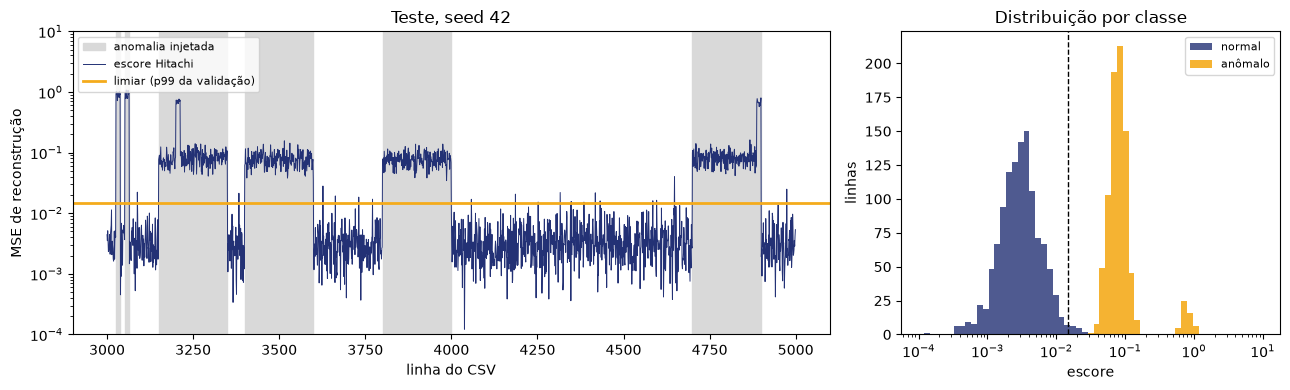

In [20]:
import matplotlib.pyplot as plt

s42 = escores[CONFIG['saved_seed']]
lim42 = por_seed.loc[CONFIG['saved_seed'], 'threshold']
linha = np.asarray(meta['test_indices'])
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={'width_ratios': [2, 1]})
a.fill_between(linha, 1e-5, 10, where=data['ytest'] == 1, color='0.85', step='mid', label='anomalia injetada')
a.plot(linha, s42, lw=0.7, color='#233175', label='escore Hitachi')
a.axhline(lim42, color='#F4AB1C', lw=2, label='limiar (p99 da validação)')
a.set(yscale='log', ylim=(1e-4, 10), xlabel='linha do CSV', ylabel='MSE de reconstrução', title='Teste, seed 42')
a.legend(loc='upper left', fontsize=8)
bins = np.logspace(-4, 1, 60)
b.hist(s42[data['ytest'] == 0], bins=bins, color='#233175', alpha=0.8, label='normal')
b.hist(s42[data['ytest'] == 1], bins=bins, color='#F4AB1C', alpha=0.9, label='anômalo')
b.axvline(lim42, color='black', ls='--', lw=1)
b.set(xscale='log', xlabel='escore', ylabel='linhas', title='Distribuição por classe')
b.legend(fontsize=8)
fig.tight_layout()
plt.show()

In [21]:
margem = pd.DataFrame({
    'menor escore anômalo / limiar': [min(escores[s][data['ytest'] == 1]) / por_seed.loc[s, 'threshold'] for s in CONFIG['seeds']]
    + [escore_base[data['ytest'] == 1].min() / base['threshold']],
    'falsos positivos': list(por_seed['fp']) + [base['fp']]},
    index=[f'Hitachi seed {s}' for s in CONFIG['seeds']] + ['baseline'])
margem.round(1)

,menor escore anômalo / limiar,falsos positivos
Hitachi seed 11,4.5,13
Hitachi seed 22,2.1,7
Hitachi seed 33,9.8,11
Hitachi seed 42,2.4,18
Hitachi seed 55,4.1,7
baseline,10.1,15


Por que as notas são tão altas? Os deslocamentos ficam entre 10 e 46 desvios-padrão da variação normal. O menor escore anômalo fica de 2 a 10 vezes acima do limiar, no Hitachi e no baseline. Qualquer método razoável separa as classes.

Um detalhe chama atenção no gráfico: o erro do Hitachi nas anomalias fica perto de 0,1, embora o deslocamento seja de dezenas de desvios-padrão. A rede reconstrói boa parte do degrau, e sua margem sobre o limiar é menor que a do baseline. Isso combina com a ausência de gargalo, mas não testamos outra arquitetura para confirmar. Os erros que sobram são normais do teste que passaram do percentil 99 da validação, o que o próprio limiar já prevê.

O que o experimento mostra: o Hitachi treina e pontua dentro do framework do tutorial, com o sentido do escore correto e resultado estável entre seeds. O que ele não mostra: que o Hitachi seja melhor que o baseline ou que o GANF, ou que funcione em equipamento real.

## 8. Limitações <a id="limites" name="limites"></a>

- Um único arquivo sintético e uma divisão temporal fixa. Não há dados reais nem outros conjuntos.
- As anomalias são degraus constantes e enormes. Desvios pequenos, deriva lenta ou ruído mudariam o quadro, e isso não foi testado.
- O GANF não foi reexecutado neste protocolo. Não há comparação Hitachi × GANF.
- O conjunto acústico não foi usado.
- A camada de 8 unidades não comprime seis entradas. O modelo detecta as anomalias porque elas ficam muito fora da faixa vista no treino. A seção 7 mostra que o erro nas anomalias é pequeno em termos absolutos; o mecanismo não foi investigado a fundo.
- No `StandardPredictor` do tutorial, o caminho `pointwise=False` falha (`y_hat_list = [], y_true_list = []` levanta `ValueError`). Usamos `pointwise=True`, que funciona; o arquivo do tutorial não foi alterado.
- Os números registrados vêm de Python 3.12, PyTorch 2.5.1 em CPU. Outra versão do PyTorch, como a do Colab, pode mudar alguns falsos positivos.

## 9. Testes e reprodução <a id="testes" name="testes"></a>

Os testes de `tests/test_atividade4.py` cobrem os intervalos, a separação dos conjuntos, o gerador aleatório, as métricas e a integração com treinador e preditor reais.

In [22]:
import unittest

suite = unittest.defaultTestLoader.loadTestsFromName('tests.test_atividade4')
resultado = unittest.TextTestRunner(verbosity=2, stream=sys.stdout).run(suite)
assert resultado.wasSuccessful()

test_chronological_holdout_and_training_are_separate (tests.test_atividade4.DataTests.test_chronological_holdout_and_training_are_separate) ... 

ok


test_default_start_creates_nonempty_interval (tests.test_atividade4.DataTests.test_default_start_creates_nonempty_interval) ... 

ok


test_explicit_zero_start_is_respected (tests.test_atividade4.DataTests.test_explicit_zero_start_is_respected) ... 

...

test_score_direction_and_channel_adaptation (tests.test_atividade4.HitachiIntegrationTests.test_score_direction_and_channel_adaptation) ... 

ok


test_trainer_and_predictor_execute_with_one_score_per_row (tests.test_atividade4.HitachiIntegrationTests.test_trainer_and_predictor_execute_with_one_score_per_row) ... 

ok


----------------------------------------------------------------------
Ran 13 tests in 0.152s

OK


In [23]:
# Resultados registrados na execução de referência (atividade4/resultados/resultados.json).
REFERENCIA = {
 "f1_mean": 0.9932720756997174,
 "f1_sd": 0.0027464067210780127,
 "baseline_f1": 0.991001799640072,
 "f1_by_seed": {
  "11": 0.9921921921921922,
  "22": 0.9957805907172996,
  "33": 0.9933854479855683,
  "42": 0.9892215568862276,
  "55": 0.9957805907172996
 },
 "environment": {
  "python": "3.12.14",
  "torch": "2.5.1+cpu",
  "numpy": "2.3.5",
  "pandas": "3.0.1"
 }
}
f1_agora = {str(s): float(por_seed.loc[s, 'f1']) for s in CONFIG['seeds']}
iguais = all(abs(f1_agora[s] - REFERENCIA['f1_by_seed'][s]) < 1e-9 for s in f1_agora)
print('Ambiente de referência:', REFERENCIA['environment'])
print('Ambiente atual: python', sys.version.split()[0], '| torch', torch.__version__)
print('F1 por seed igual ao registrado:', iguais)
if not iguais:
    print('Diferença esperada se a versão do PyTorch ou o hardware mudarem. Compare a tabela da seção 6.')
assert abs(base['f1'] - REFERENCIA['baseline_f1']) < 1e-9, 'O baseline não depende do PyTorch e deveria ser idêntico.'


Ambiente de referência: {'python': '3.12.14', 'torch': '2.5.1+cpu', 'numpy': '2.3.5', 'pandas': '3.0.1'}
Ambiente atual: python 3.12.14 | torch 2.5.1+cpu
F1 por seed igual ao registrado: True


Para repetir fora do notebook, na raiz do repositório com as dependências de `requirements-atividade4.txt`:

```bash
python -m pytest tests/test_atividade4.py -q
python -m atividade4.experimento
```

## 10. Respostas para a apresentação e referências <a id="apresentacao" name="apresentacao"></a>

**Qual foi a parte mais desafiadora?** Confiar nos dados antes de confiar no modelo. O erro do intervalo não quebra nada: o código roda e as métricas saem. Só aparece quando se conta quantas linhas foram de fato alteradas. Depois, foi preciso separar o que era correção do erro do que era mudança de protocolo (a montagem do teste) e entender por que qualquer método tirava nota perto de 1.

**Conclusão da Parte I.** O primeiro intervalo de `set_abnormal_data` usava `step` como fim, enquanto os outros três o usam como duração. Com início 200 e `step=13`, a fatia `[200:13]` fica vazia; com início 150 e `step=200`, entram 50 linhas em vez de 200. O teste original tinha 676 anomalias em vez de 826. A correção usa fim = início + duração e aceita início zero. A montagem por classe do teste original também foi trocada por blocos cronológicos, numa mudança registrada à parte.

**Conclusão da Parte II.** O Hitachi do tutorial foi integrado ao mesmo fluxo do GANF: `get_dataloader`, `MSELoss`, Adam, `UnsupervisedTrainer` e `StandardPredictor`, com o adaptador `HitachiScore`. No teste cronológico, F1 médio de 0,993 (desvio 0,003 entre cinco seeds), recall 1,0 e ROC-AUC perto de 1. O baseline sem treino teve F1 0,991. As anomalias sintéticas são grandes demais para diferenciar os métodos.

### Referências
- Repositório do tutorial: [github.com/CristoferSilva/mtsa-tutorial-compet](https://github.com/CristoferSilva/mtsa-tutorial-compet), commit `a5959467eca45f930341783a7006affcae5e6e88`.
- Exemplo do GANF: `examples/MTSA.ipynb` do mesmo repositório.
- Wu, Park e Tirthapura. Graph-augmented normalizing flows for anomaly detection of multiple time series. AAAI, 2022. DOI 10.1609/aaai.v36i8.20829 (citado no código do GANF).
- Material da aula de Ciência de Dados do COMPET Moura, 12/10/2026.